In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

# 비음수 행렬 분해(Non-negative Matrix Factorization, NMF)

비음수 행렬 분해는 행렬 내 모든 `원소값이 0이상인 경우 사용`할 수 있는 행렬 분해 방법이다.

비음수 행렬 분해 알고리즘을 이용해서 사이킷런이 제공하는 얼굴 이미지 데이터에서 사람 얼굴의 특징 요소를 추출하는 모델을 생성해 본다.  
비음수 행렬 분해에서 사용하는 데이터는 성분이 모두 음수가 아닌 성분이어야 하므로 주로 `이미지 데이터`나 `음성 데이터`와 같이 음수값이 없는 데이터가 많이 사용된다.

## 사이킷런이 제공하는 컬러 얼굴 이미지 데이터를 불러온다.

fetch_lfw_people() 메소드를 사용해서 얼굴 이미지를 컬러로 읽어온다.

`min_faces_per_person`의 기본값은 0이고 얼굴 이미지 데이터 중 지정한 값 이상 같은 인물이 있는 얼굴 이미지 데이터만 얻어온다.  
`resize`의 기본값은 0.5이고 얼굴 이미지 데이터의 원본 대비 크기를 지정한다.  
`color`의 기본값은 False이고 흑백 이미지로 얻어오고 True를 지정하면 컬러 이미지로 얻어온다.

In [2]:
raw_data = datasets.fetch_lfw_people(min_faces_per_person=20, resize=1.0, color=True)

## 사이킷런이 제공하는 컬러 얼굴 이미지 살펴보기

컬러 이미지의 각 픽셀은 채널(RGB)별로 0에서 255 사이의 값을 가지며 채널의 개수는 3개이다.

raw_data.images는 채널이 3개인 얼굴 이미지이고 raw_data.data는 얼굴 이미지를 1차원으로 변경해놓은 데이터이다.

In [9]:
print(raw_data.images.shape)
n, h, w, c = raw_data.images.shape
print(f'읽어온 이미지 개수: {n}, 이미지 세로 크기: {h}, 이미지 가로 크기: {w}, 채널 개수: {c}')

(3023, 125, 94, 3)
읽어온 이미지 개수: 3023, 이미지 세로 크기: 125, 이미지 가로 크기: 94, 채널 개수: 3


In [17]:
xData = raw_data.data # 피처(얼굴 이미지)
# 35250이 출력되는 이유는 이미지 한 장을 1차원으로 펼쳐서 세로 크기(125) * 가로 크기(94) * 채널 개수(3)를 연산한 결과가 35250이기 때문이다.
print(xData.shape)
yData = raw_data.target # 피처에 따른 레이블(얼굴 이미지에 따른 얼굴 주인 이름)
target_names = raw_data.target_names
print(f'{xData.shape[0]}개의 얼굴 이미지를 구성하는 인물의 수는 {len(target_names)}명 이다.')

(3023, 35250)
3023개의 얼굴 이미지를 구성하는 인물의 수는 62명 이다.


In [13]:
x_train, x_test, y_train, y_test = train_test_split(xData, yData, random_state=1)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(2267, 35250) (756, 35250) (2267,) (756,)


## 비음수 행렬 분해 전 오리지널 컬러 이미지 시각화

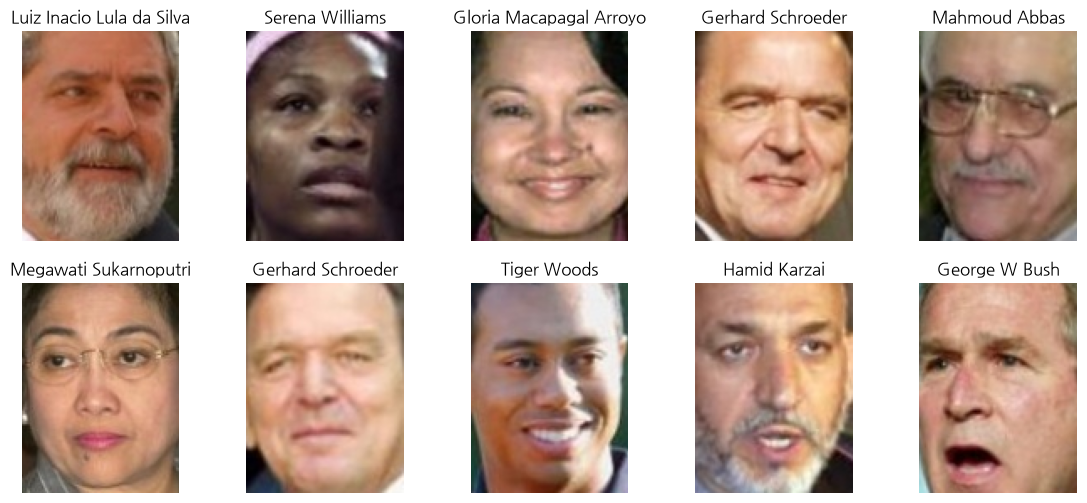

In [22]:
plt.figure(figsize=[14, 6])
for i in range(10):
    plt.subplot(2, 5, i + 1)
    # x_train에는 1차원으로 펼쳐진 이미지 데이터가 저장된 상태이므로 reshape() 메소드로 2차원 이미지로 변환한다. 컬러 이미지기 때문에 3을 붙여준다.
    plt.imshow(x_train[i].reshape(h, w, 3))
    plt.axis('off')
    plt.title(target_names[y_train[i]])
plt.show()

## 비음수 행렬 분해 모델을 만들고 학습 시킨다.

비음수 행렬 분해 알고리즘을 사용하기 위해 NMF를 import 한다.

In [23]:
from sklearn.decomposition import NMF

n_components에 축소하려는 차원 크기를 지정해서 비음수 행렬 분해 모델을 만들고 학습한 후 적용시킨다.

In [25]:
model = NMF(n_components=10) # 35250 차원의 데이터를 10차원으로 차원을 축소한다.
# 비음수 행렬 분해도 지도 학습적인 방법이므로 학습 데이터의 피처와 학습 데이터의 피처에 따른 레이블까지 넘겨서 학습시킨다.
# model.fit(x_train, y_train)
# x_train_nmf = model.transform(x_train)
x_train_nmf = model.fit_transform(x_train, y_train)
x_test_nmf = model.transform(x_test)
print(x_train.shape, x_train_nmf.shape, x_test.shape, x_test_nmf.shape)

(2267, 35250) (2267, 10) (756, 35250) (756, 10)


## 비음수 행렬 분해 벡터를 확인한다.

components_ 속성으로 차원 축소에 사용된 비음수 행렬 분해 벡터를 얻어올 수 있다.

In [27]:
print(model.components_.shape)
print(model.components_)

(10, 35250)
[[1.1323286e+00 5.7870799e-01 1.1034734e-01 ... 1.4339329e-02
  0.0000000e+00 0.0000000e+00]
 [0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 1.4195588e+01
  1.5076804e+01 1.5349297e+01]
 [0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 0.0000000e+00
  0.0000000e+00 1.1469598e-01]
 ...
 [0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 0.0000000e+00
  1.7209353e-02 3.2556992e-02]
 [0.0000000e+00 0.0000000e+00 2.1210273e-03 ... 1.2065393e+00
  1.0473545e+00 9.5750153e-01]
 [0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 0.0000000e+00
  0.0000000e+00 0.0000000e+00]]


## 비음수 행렬 분해 후 차원 축소된 이미지 시각화

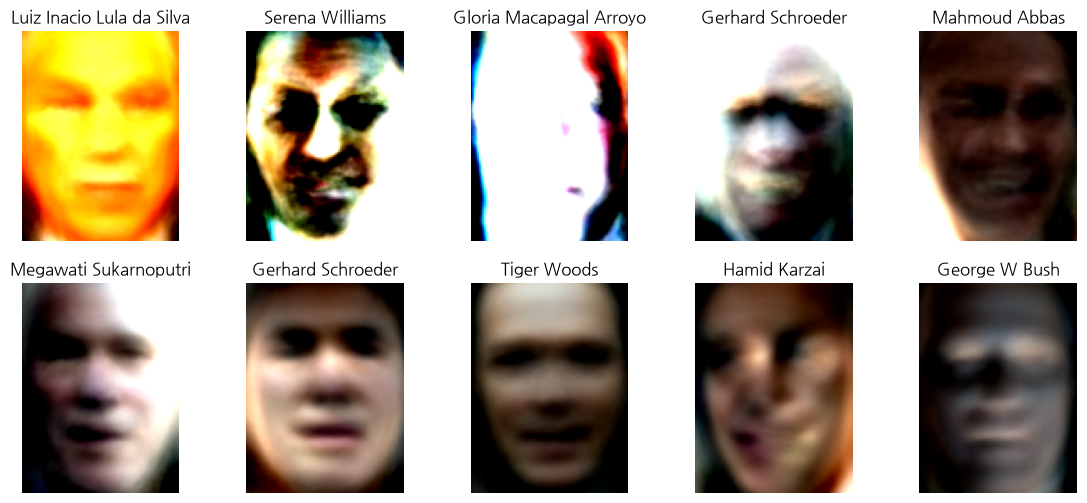

In [45]:
plt.figure(figsize=[14, 6])
for i in range(10):
    plt.subplot(2, 5, i + 1)
    # 비음수 행렬 분해 벡터는 실수 형태이므로 넘파이의 clip() 메소드로 최소값(0.0) 미만과 최대값(1.0) 초과인 데이터를 잘라낸다.
    plt.imshow(np.clip(model.components_[i].reshape(h, w, 3), 0.0, 1.0))
    plt.axis('off')
    plt.title(target_names[y_train[i]])
plt.show()

## 사이킷런이 제공하는 흑백 얼굴 이미지 데이터를 불러온다.

fetch_lfw_people() 메소드를 사용해서 얼굴 이미지를 흑백으로 읽어온다.

In [46]:
raw_data = datasets.fetch_lfw_people(min_faces_per_person=20, resize=1.0)

## 사이킷런이 제공하는 흑백 얼굴 이미지 살펴보기

흑백 이미지의 각 픽셀은 0에서 255 사이의 값을 가지며 채널의 개수는 1개이다.

raw_data.images는 채널이 1개인 얼굴 이미지이고 raw_data.data는 얼굴 이미지를 1차원으로 변경해놓은 데이터이다.

In [49]:
print(raw_data.images.shape)
n, h, w = raw_data.images.shape
print(f'읽어온 이미지 개수: {n}, 이미지 세로 크기: {h}, 이미지 가로 크기: {w}')

(3023, 125, 94)
읽어온 이미지 개수: 3023, 이미지 세로 크기: 125, 이미지 가로 크기: 94


In [51]:
xData = raw_data.data # 피처(얼굴 이미지)
# 11750이 출력되는 이유는 이미지 한 장을 1차원으로 펼쳐서 세로 크기(125) * 가로 크기(94) * 채널 개수(1)를 연산한 결과가 11750이기 때문이다.
print(xData.shape)
yData = raw_data.target # 피처에 따른 레이블(얼굴 이미지에 따른 얼굴 주인 이름)
target_names = raw_data.target_names
print(f'{xData.shape[0]}개의 얼굴 이미지를 구성하는 인물의 수는 {len(target_names)}명 이다.')

(3023, 11750)
3023개의 얼굴 이미지를 구성하는 인물의 수는 62명 이다.


In [52]:
x_train, x_test, y_train, y_test = train_test_split(xData, yData, random_state=1)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(2267, 11750) (756, 11750) (2267,) (756,)


## 비음수 행렬 분해 전 오리지널 흑백 이미지 시각화

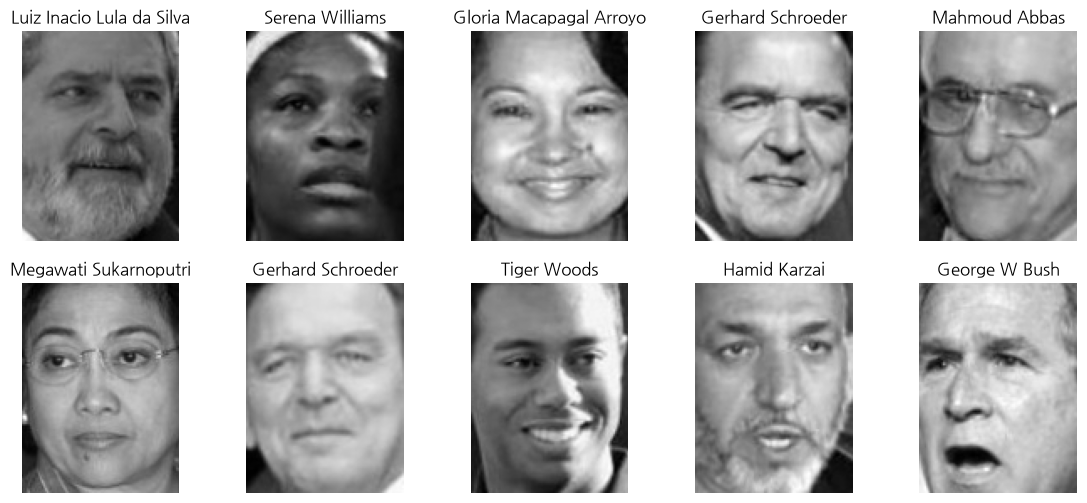

In [54]:
plt.figure(figsize=[14, 6])
for i in range(10):
    plt.subplot(2, 5, i + 1)
    # x_train에는 1차원으로 펼쳐진 이미지 데이터가 저장된 상태이므로 reshape() 메소드로 2차원 이미지로 변환한다.
    plt.imshow(x_train[i].reshape(h, w), cmap='gray')
    plt.axis('off')
    plt.title(target_names[y_train[i]])
plt.show()

## 비음수 행렬 분해 모델을 만들고 학습 시킨다.

n_components에 축소하려는 차원 크기를 지정해서 비음수 행렬 분해 모델을 만들고 학습한 후 적용시킨다.

In [55]:
model = NMF(n_components=10) # 11750 차원의 데이터를 10차원으로 차원을 축소한다.
x_train_nmf = model.fit_transform(x_train, y_train)
x_test_nmf = model.transform(x_test)
print(x_train.shape, x_train_nmf.shape, x_test.shape, x_test_nmf.shape)

(2267, 11750) (2267, 10) (756, 11750) (756, 10)


## 비음수 행렬 분해 후 차원 축소된 이미지 시각화

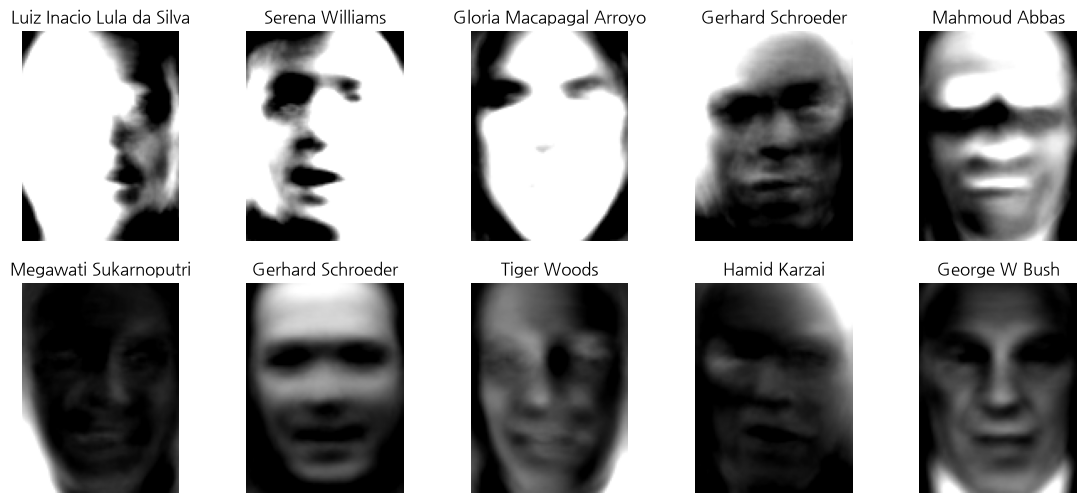

In [58]:
plt.figure(figsize=[14, 6])
for i in range(10):
    plt.subplot(2, 5, i + 1)
    # 비음수 행렬 분해 벡터는 실수 형태이므로 넘파이의 clip() 메소드로 최소값(0.0) 미만과 최대값(1.0) 초과인 데이터를 잘라낸다.
    plt.imshow(np.clip(model.components_[i].reshape(h, w), 0.0, 1.0), cmap='gray')
    plt.axis('off')
    plt.title(target_names[y_train[i]])
plt.show()